# Machine Learning Engineer Nanodegree
## Unsupervised Learning
## Project: Creating Customer Segments

Welcome to the third project of the Machine Learning Engineer Nanodegree! In this notebook, some template code has already been provided for you, and it will be your job to implement the additional functionality necessary to successfully complete this project. Sections that begin with **'Implementation'** in the header indicate that the following block of code will require additional functionality which you must provide. Instructions will be provided for each section and the specifics of the implementation are marked in the code block with a `'TODO'` statement. Please be sure to read the instructions carefully!

In addition to implementing code, there will be questions that you must answer which relate to the project and your implementation. Each section where you will answer a question is preceded by a **'Question X'** header. Carefully read each question and provide thorough answers in the following text boxes that begin with **'Answer:'**. Your project submission will be evaluated based on your answers to each of the questions and the implementation you provide.  

>**Note:** Code and Markdown cells can be executed using the **Shift + Enter** keyboard shortcut. In addition, Markdown cells can be edited by typically double-clicking the cell to enter edit mode.

## Getting Started

In this project, you will analyze a dataset containing data on various customers' annual spending amounts (reported in *monetary units*) of diverse product categories for internal structure. One goal of this project is to best describe the variation in the different types of customers that a wholesale distributor interacts with. Doing so would equip the distributor with insight into how to best structure their delivery service to meet the needs of each customer.

The dataset for this project can be found on the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Wholesale+customers). For the purposes of this project, the features `'Channel'` and `'Region'` will be excluded in the analysis — with focus instead on the six product categories recorded for customers.

Run the code block below to load the wholesale customers dataset, along with a few of the necessary Python libraries required for this project. You will know the dataset loaded successfully if the size of the dataset is reported.

In [1]:
# Import libraries necessary for this project
import numpy as np
import pandas as pd
from IPython.display import display # Allows the use of display() for DataFrames

# Import supplementary visualizations code visuals.py
import visuals as vs

# Pretty display for notebooks
%matplotlib inline

# Load the wholesale customers dataset
try:
    data = pd.read_csv("customers.csv")
    data.drop(['Region', 'Channel'], axis = 1, inplace = True)
    print("Wholesale customers dataset has {} samples with {} features each.".format(*data.shape))
except:
    print("Dataset could not be loaded. Is the dataset missing?")

Wholesale customers dataset has 440 samples with 6 features each.


## Data Exploration
In this section, you will begin exploring the data through visualizations and code to understand how each feature is related to the others. You will observe a statistical description of the dataset, consider the relevance of each feature, and select a few sample data points from the dataset which you will track through the course of this project.

Run the code block below to observe a statistical description of the dataset. Note that the dataset is composed of six important product categories: **'Fresh'**, **'Milk'**, **'Grocery'**, **'Frozen'**, **'Detergents_Paper'**, and **'Delicatessen'**. Consider what each category represents in terms of products you could purchase.

In [2]:
# Display a description of the dataset
display(data.describe())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### Implementation: Selecting Samples
To get a better understanding of the customers and how their data will transform through the analysis, it would be best to select a few sample data points and explore them in more detail. In the code block below, add **three** indices of your choice to the `indices` list which will represent the customers to track. It is suggested to try different sets of samples until you obtain customers that vary significantly from one another.

In [3]:
# TODO: Select three indices of your choice you wish to sample from the dataset
indices = [47,128,330]

# Create a DataFrame of the chosen samples
samples = pd.DataFrame(data.loc[indices], columns = data.keys()).reset_index(drop = True)
print("Chosen samples of wholesale customers dataset:")
display(samples)

Chosen samples of wholesale customers dataset:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,44466,54259,55571,7782,24171,6465
1,140,8847,3823,142,1062,3
2,9790,1786,5109,3570,182,1043


### Question 1
Consider the total purchase cost of each product category and the statistical description of the dataset above for your sample customers.  

* What kind of establishment (customer) could each of the three samples you've chosen represent?

**Hint:** Examples of establishments include places like markets, cafes, delis, wholesale retailers, among many others. Avoid using names for establishments, such as saying *"McDonalds"* when describing a sample customer as a restaurant. You can use the mean values for reference to compare your samples with. The mean values are as follows:

* Fresh: 12000.2977
* Milk: 5796.2
* Grocery: 7951.3
* Frozen: 3071.9
* Detergents_paper: 2881.4
* Delicatessen: 1524.8

Knowing this, how do your samples compare? Does that help in driving your insight into what kind of establishments they might be? 


**Answer:**
Sample 1 (The Heavy Hitter)

Parsed Spending: Fresh: 44,466 | Milk: 54,259 | Grocery: 55,571 | Frozen: 7,782 | Detergents: 24,171 | Deli: 6,465

Comparison: This customer spends massively across the board. Their spending on Milk, Grocery, and Detergents is roughly 10 times the average.

Establishment Guess: A large supermarket, a bulk wholesale retailer, or a massive hotel/resort. Only huge businesses buy groceries and paper products at this scale.

Sample 2 (The Fresh Focus)

Parsed Spending: Fresh: 14,088 | Milk: 4,738 | Grocery: 2,314 | Frozen: 2,106 | Detergents: 2,329 | Deli: 790

Comparison: Fresh food is the only category above the dataset average (12,000). Groceries and Deli are significantly below average.

Establishment Guess: A standard restaurant or a fresh produce market. They prioritize raw, fresh ingredients to cook with, rather than buying pre-packaged groceries or deli meats.

Sample 3 (The Frozen Buyer)

Parsed Spending: Fresh: 9,790 | Milk: 1,786 | Grocery: 5,109 | Frozen: 3,570 | Detergents: 182 | Deli: 1,043

Comparison: Frozen food is above the 3,071 average, while Detergents & Paper is exceptionally low (182 compared to the 2,881 average). Milk is also barely utilized.

Establishment Guess: A small convenience store or a fast-food deli. They stock up on frozen goods and basic groceries but have virtually no need for bulk cleaning supplies or fresh dairy.

### Implementation: Feature Relevance
One interesting thought to consider is if one (or more) of the six product categories is actually relevant for understanding customer purchasing. That is to say, is it possible to determine whether customers purchasing some amount of one category of products will necessarily purchase some proportional amount of another category of products? We can make this determination quite easily by training a supervised regression learner on a subset of the data with one feature removed, and then score how well that model can predict the removed feature.

In the code block below, you will need to implement the following:
 - Assign `new_data` a copy of the data by removing a feature of your choice using the `DataFrame.drop` function.
 - Use `sklearn.model_selection.train_test_split` to split the dataset into training and testing sets.
   - Use the removed feature as your target label. Set a `test_size` of `0.25` and set a `random_state`.
 - Import a decision tree regressor, set a `random_state`, and fit the learner to the training data.
 - Report the prediction score of the testing set using the regressor's `score` function.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor


for feature in data.columns:
    new_data = data.drop(feature,axis=1)
    target = data[feature]
    X_train, X_test, y_train, y_test = train_test_split(new_data, target, test_size=0.25, random_state=42)
    regressor = DecisionTreeRegressor(random_state=42)
    regressor.fit(X_train, y_train)
    score = regressor.score(X_test, y_test)
    print(f"Score for predicting {feature}: {score:.4f}")



# TODO: Make a copy of the DataFrame, using the 'drop' function to drop the given feature


# TODO: Split the data into training and testing sets(0.25) using the given feature as the target
# Set a random state.

# TODO: Create a decision tree regressor and fit it to the training set


# TODO: Report the score of the prediction using the testing set


Score for predicting Fresh: -0.3857
Score for predicting Milk: 0.1563
Score for predicting Grocery: 0.6819
Score for predicting Frozen: -0.2101
Score for predicting Detergents_Paper: 0.2717
Score for predicting Delicatessen: -2.2547


### Question 2

* Which feature did you attempt to predict? 
* What was the reported prediction score? 
* Is this feature necessary for identifying customers' spending habits?

**Hint:** The coefficient of determination, `R^2`, is scored between 0 and 1, with 1 being a perfect fit. A negative `R^2` implies the model fails to fit the data. If you get a low score for a particular feature, that lends us to beleive that that feature point is hard to predict using the other features, thereby making it an important feature to consider when considering relevance.

**Answer:**
I ran the code for each feature and the score isn't so high. the highest score is 0.68 for grocery which isn't too high. So, for this phase, I don't recommend to drop any feature.

### Visualize Feature Distributions
To get a better understanding of the dataset, we can construct a scatter matrix of each of the six product features present in the data. If you found that the feature you attempted to predict above is relevant for identifying a specific customer, then the scatter matrix below may not show any correlation between that feature and the others. Conversely, if you believe that feature is not relevant for identifying a specific customer, the scatter matrix might show a correlation between that feature and another feature in the data. Run the code block below to produce a scatter matrix.

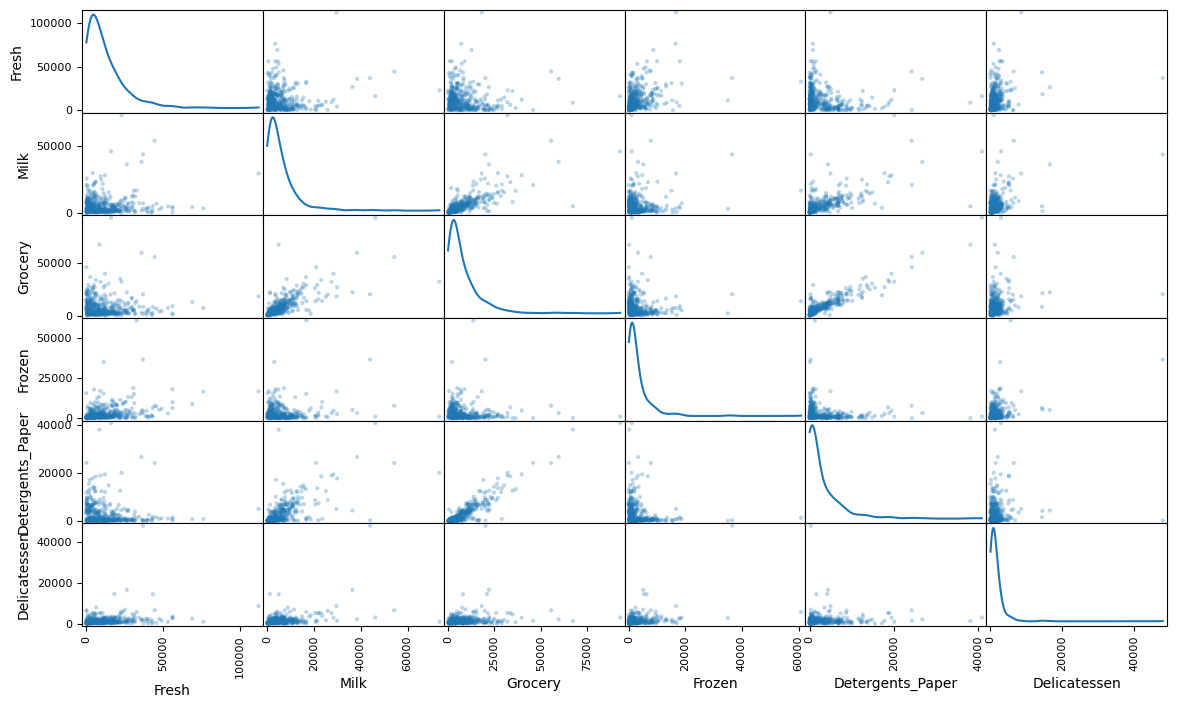

In [5]:
# Produce a scatter matrix for each pair of features in the data
pd.plotting.scatter_matrix(data, alpha = 0.3, figsize = (14,8), diagonal = 'kde');

### Question 3
* Using the scatter matrix as a reference, discuss the distribution of the dataset, specifically talk about the normality, outliers, large number of data points near 0 among others. If you need to sepearate out some of the plots individually to further accentuate your point, you may do so as well.
* Are there any pairs of features which exhibit some degree of correlation? 
* Does this confirm or deny your suspicions about the relevance of the feature you attempted to predict? 
* How is the data for those features distributed?

**Hint:** Is the data normally distributed? Where do most of the data points lie? You can use [corr()](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.corr.html) to get the feature correlations and then visualize them using a [heatmap](http://seaborn.pydata.org/generated/seaborn.heatmap.html)(the data that would be fed into the heatmap would be the correlation values, for eg: `data.corr()`) to gain further insight.

Distribution, Normality, and Outliers: The data is highly right-skewed and not normally distributed. The density plots on the diagonal show sharp peaks near zero, meaning the vast majority of customers spend relatively small amounts across all categories. The long tails extending to the right, along with scattered points far from the main clusters in the scatter plots, indicate the presence of significant high-spending outliers in every category.   Correlated Features: The scatter plots reveal clear positive correlations where the data forms a distinct upward-sloping shape rather than a random cloud. The strongest linear correlation is between Grocery and Detergents_Paper. There is also a solid correlation between Grocery and Milk, and a moderate correlation between Milk and Detergents_Paper.   Confirming Feature Relevance: This visual perfectly confirms why Grocery received a high $R^2$ prediction score in your previous step. The model could accurately predict Grocery spending because it heavily mirrors the spending patterns of Detergents_Paper and Milk.   Distribution of Correlated Features: Even though Grocery, Milk, and Detergents_Paper share a relationship, their individual data distributions remain strongly right-skewed with most data points clustered near zero.   

## Data Preprocessing
In this section, you will preprocess the data to create a better representation of customers by performing a scaling on the data and detecting (and optionally removing) outliers. Preprocessing data is often times a critical step in assuring that results you obtain from your analysis are significant and meaningful.

### Implementation: Feature Scaling
If data is not normally distributed, especially if the mean and median vary significantly (indicating a large skew), it is most [often appropriate](http://econbrowser.com/archives/2014/02/use-of-logarithms-in-economics) to apply a non-linear scaling — particularly for financial data. One way to achieve this scaling is by using a [Box-Cox test](http://scipy.github.io/devdocs/generated/scipy.stats.boxcox.html), which calculates the best power transformation of the data that reduces skewness. A simpler approach which can work in most cases would be applying the natural logarithm.

In the code block below, you will need to implement the following:
 - Assign a copy of the data to `log_data` after applying logarithmic scaling. Use the `np.log` function for this.
 - Assign a copy of the sample data to `log_samples` after applying logarithmic scaling. Again, use `np.log`.

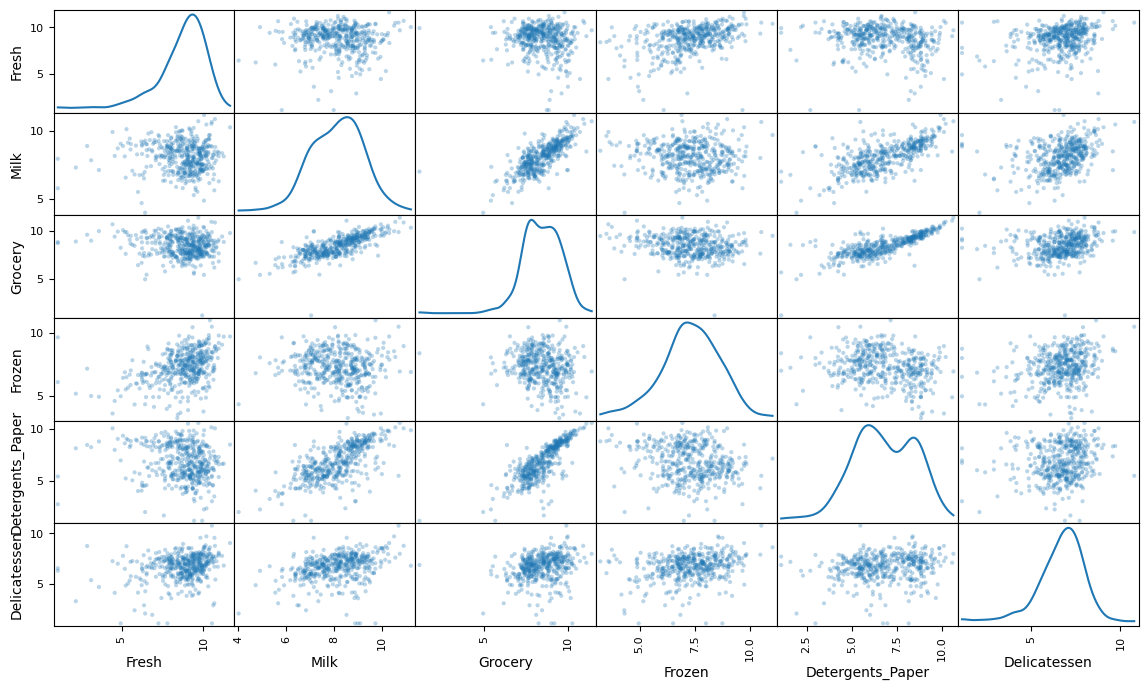

In [7]:
# TODO: Scale the data using the natural logarithm
log_data = np.log(data)

# TODO: Scale the sample data using the natural logarithm
log_samples = np.log(samples)

# Produce a scatter matrix for each pair of newly-transformed features
pd.plotting.scatter_matrix(log_data, alpha = 0.3, figsize = (14,8), diagonal = 'kde');

### Observation
After applying a natural logarithm scaling to the data, the distribution of each feature should appear much more normal. For any pairs of features you may have identified earlier as being correlated, observe here whether that correlation is still present (and whether it is now stronger or weaker than before).

Run the code below to see how the sample data has changed after having the natural logarithm applied to it.

In [8]:
# Display the log-transformed sample data
display(log_samples)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,10.702480,10.901524,10.925417,8.959569,10.092909,8.774158
1,4.941642,9.087834,8.248791,4.955827,6.967909,1.098612
2,9.189117,7.487734,8.538759,8.180321,5.204007,6.949856


### Implementation: Outlier Detection
Detecting outliers in the data is extremely important in the data preprocessing step of any analysis. The presence of outliers can often skew results which take into consideration these data points. There are many "rules of thumb" for what constitutes an outlier in a dataset. Here, we will use [Tukey's Method for identfying outliers](http://datapigtechnologies.com/blog/index.php/highlighting-outliers-in-your-data-with-the-tukey-method/): An *outlier step* is calculated as 1.5 times the interquartile range (IQR). A data point with a feature that is beyond an outlier step outside of the IQR for that feature is considered abnormal.

In the code block below, you will need to implement the following:
 - Assign the value of the 25th percentile for the given feature to `Q1`. Use `np.percentile` for this.
 - Assign the value of the 75th percentile for the given feature to `Q3`. Again, use `np.percentile`.
 - Assign the calculation of an outlier step for the given feature to `step`.
 - Optionally remove data points from the dataset by adding indices to the `outliers` list.

**NOTE:** If you choose to remove any outliers, ensure that the sample data does not contain any of these points!  
Once you have performed this implementation, the dataset will be stored in the variable `good_data`.

In [13]:
# For each feature find the data points with extreme high or low values
for feature in log_data.keys():
    
    # TODO: Calculate Q1 (25th percentile of the data) for the given feature
    Q1 = np.percentile(log_data[feature], 25)
    
    # TODO: Calculate Q3 (75th percentile of the data) for the given feature
    Q3 = np.percentile(log_data[feature], 75)
    
    # TODO: Use the interquartile range to calculate an outlier step (1.5 times the interquartile range)
    step = 1.5 * (Q3 - Q1)
    
    # Display the outliers
    print("Data points considered outliers for the feature '{}':".format(feature))
    feature_outliers = log_data[~((log_data[feature] >= Q1 - step) & (log_data[feature] <= Q3 + step))]
    # display(feature_outliers)
    print(len(feature_outliers))
    
# We only remove data points that are outliers in multiple categories to preserve data.
outliers  = [65, 66, 75, 128, 154]

# Remove the outliers, if any were specified
good_data = log_data.drop(log_data.index[outliers]).reset_index(drop = True)

Data points considered outliers for the feature 'Fresh':
16
Data points considered outliers for the feature 'Milk':
4
Data points considered outliers for the feature 'Grocery':
2
Data points considered outliers for the feature 'Frozen':
10
Data points considered outliers for the feature 'Detergents_Paper':
2
Data points considered outliers for the feature 'Delicatessen':
14


### Question 4
* Are there any data points considered outliers for more than one feature based on the definition above? 
* Should these data points be removed from the dataset? 
* If any data points were added to the `outliers` list to be removed, explain why.

** Hint: ** If you have datapoints that are outliers in multiple categories think about why that may be and if they warrant removal. Also note how k-means is affected by outliers and whether or not this plays a factor in your analysis of whether or not to remove them.

**Answer:**
Multi-feature outliers: Yes, based on Tukey's method, several data points are considered outliers for more than one feature. Specifically, indices 65, 66, 75, 128, and 154 appeared across multiple categories.

Should they be removed? Yes, these specific multi-feature outliers should be removed from the dataset.

Reasoning and K-Means Impact: I added these specific indices to the outliers list because removing every single-feature outlier would discard nearly 10% of the dataset, losing too much valuable information. However, multi-feature outliers are extreme anomalies that must be handled. K-Means clustering relies on distance metrics (like Euclidean distance) to calculate cluster centers. Extreme outliers will pull the cluster centroids away from the true dense groupings of the data, leading to inaccurate and skewed customer segments. Removing only the most extreme cases strikes the right balance between data retention and model accuracy.

## Feature Transformation
In this section you will use principal component analysis (PCA) to draw conclusions about the underlying structure of the wholesale customer data. Since using PCA on a dataset calculates the dimensions which best maximize variance, we will find which compound combinations of features best describe customers.

### Implementation: PCA

Now that the data has been scaled to a more normal distribution and has had any necessary outliers removed, we can now apply PCA to the `good_data` to discover which dimensions about the data best maximize the variance of features involved. In addition to finding these dimensions, PCA will also report the *explained variance ratio* of each dimension — how much variance within the data is explained by that dimension alone. Note that a component (dimension) from PCA can be considered a new "feature" of the space, however it is a composition of the original features present in the data.

In the code block below, you will need to implement the following:
 - Import `sklearn.decomposition.PCA` and assign the results of fitting PCA in six dimensions with `good_data` to `pca`.
 - Apply a PCA transformation of `log_samples` using `pca.transform`, and assign the results to `pca_samples`.

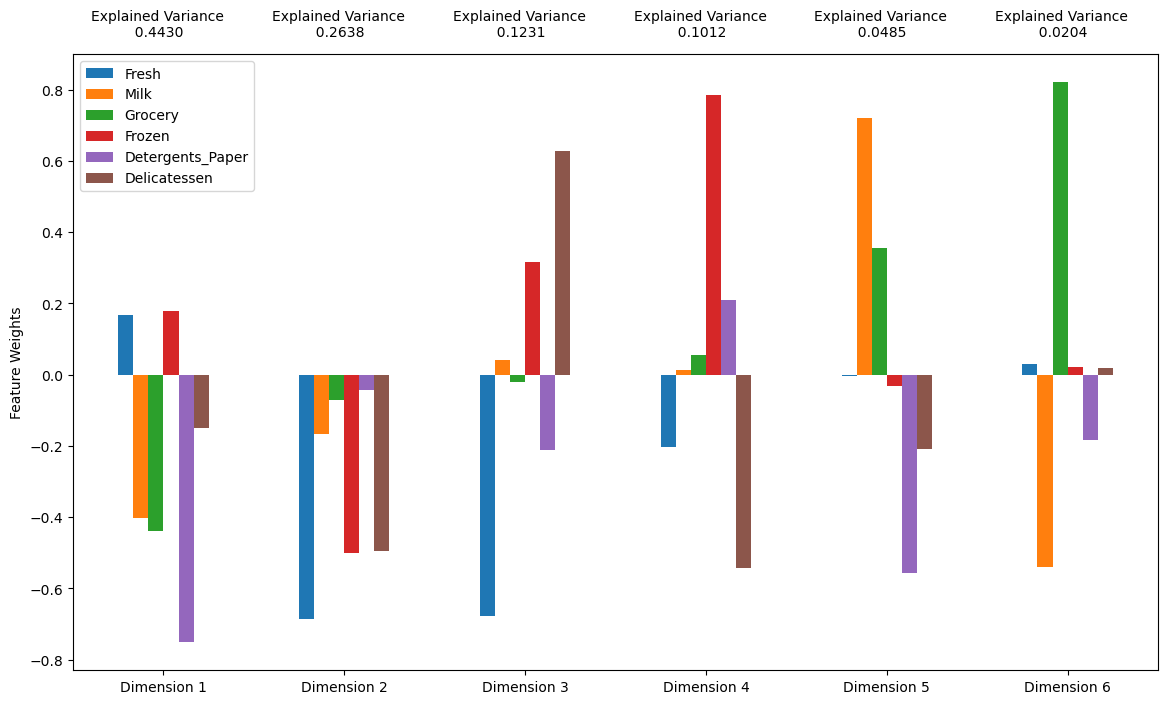

In [17]:
from sklearn.decomposition import PCA
#  TODO: Apply PCA by fitting the good data with the same number of dimensions as features
pca = PCA(n_components=6)
pca.fit(good_data)

# TODO: Transform log_samples using the PCA fit above
pca_samples = pca.transform(log_samples)

# Generate PCA results plot
pca_results = vs.pca_results(good_data, pca)

### Question 5

* How much variance in the data is explained* **in total** *by the first and second principal component? 
* How much variance in the data is explained by the first four principal components? 
* Using the visualization provided above, talk about each dimension and the cumulative variance explained by each, stressing upon which features are well represented by each dimension(both in terms of positive and negative variance explained). Discuss what the first four dimensions best represent in terms of customer spending.

**Hint:** A positive increase in a specific dimension corresponds with an *increase* of the *positive-weighted* features and a *decrease* of the *negative-weighted* features. The rate of increase or decrease is based on the individual feature weights.

**Answer:**
Variance of First and Second Components: The first and second principal components explain a total of 70.68% of the variance in the data (44.30% + 26.38%).   
Variance of First Four Components: The first four principal components explain a total of 93.11% of the variance in the data (44.30% + 26.38% + 12.31% + 10.12%).   
Dimension Breakdown and Customer Spending Profiles:
Dimension 1 (44.30% cumulative): This dimension is heavily driven by large negative weights for Detergents_Paper, Grocery, and Milk. Because they all share the same sign, they move together. A customer with a high profile in this dimension buys these three categories in bulk, which strongly represents Retailers or Supermarkets.   
Dimension 2 (70.68% cumulative): This dimension is dominated by large negative weights for Fresh, Frozen, and Delicatessen. A customer profiled by this dimension primarily purchases ingredients for preparing food, which best represents Restaurants, Cafes, or Eateries. 
Dimension 3 (82.99% cumulative): This dimension contrasts a large positive weight for Delicatessen and Frozen against a large negative weight for Fresh and Detergents_Paper. This represents a specialized establishment that relies heavily on pre-prepared meats/deli items and frozen goods while actively avoiding raw fresh produce, such as a Deli or Fast-Food sandwich shop.   
Dimension 4 (93.11% cumulative): This dimension shows a massive positive weight for Frozen and a strong negative weight for Delicatessen and Fresh. This represents a customer uniquely focused on frozen goods over all other food types, such as a Frozen Food Retailer or specialized seafood/meat importer.  

### Observation
Run the code below to see how the log-transformed sample data has changed after having a PCA transformation applied to it in six dimensions. Observe the numerical value for the first four dimensions of the sample points. Consider if this is consistent with your initial interpretation of the sample points.

In [18]:
# Display sample log-data after having a PCA transformation applied
display(pd.DataFrame(np.round(pca_samples, 4), columns = pca_results.index.values))

,Dimension 1,Dimension 2,Dimension 3,Dimension 4,Dimension 5,Dimension 6
0,-4.3646,-3.9519,-0.1229,0.6240,0.5379,0.0551
1,-0.6435,6.4218,-1.6655,1.9916,1.7796,-0.9933
2,1.6063,-0.6751,0.4544,0.1091,0.3745,0.7363


### Implementation: Dimensionality Reduction
When using principal component analysis, one of the main goals is to reduce the dimensionality of the data — in effect, reducing the complexity of the problem. Dimensionality reduction comes at a cost: Fewer dimensions used implies less of the total variance in the data is being explained. Because of this, the *cumulative explained variance ratio* is extremely important for knowing how many dimensions are necessary for the problem. Additionally, if a signifiant amount of variance is explained by only two or three dimensions, the reduced data can be visualized afterwards.

In the code block below, you will need to implement the following:
 - Assign the results of fitting PCA in two dimensions with `good_data` to `pca`.
 - Apply a PCA transformation of `good_data` using `pca.transform`, and assign the results to `reduced_data`.
 - Apply a PCA transformation of `log_samples` using `pca.transform`, and assign the results to `pca_samples`.

In [19]:
# TODO: Apply PCA by fitting the good data with only two dimensions
pca = PCA(n_components=2)
pca.fit(good_data)

# TODO: Transform the good data using the PCA fit above
reduced_data = pca.transform(good_data)

# TODO: Transform log_samples using the PCA fit above
pca_samples = pca.transform(log_samples)

# Create a DataFrame for the reduced data
reduced_data = pd.DataFrame(reduced_data, columns = ['Dimension 1', 'Dimension 2'])

### Observation
Run the code below to see how the log-transformed sample data has changed after having a PCA transformation applied to it using only two dimensions. Observe how the values for the first two dimensions remains unchanged when compared to a PCA transformation in six dimensions.

In [20]:
# Display sample log-data after applying PCA transformation in two dimensions
display(pd.DataFrame(np.round(pca_samples, 4), columns = ['Dimension 1', 'Dimension 2']))

,Dimension 1,Dimension 2
0,-4.3646,-3.9519
1,-0.6435,6.4218
2,1.6063,-0.6751


## Visualizing a Biplot
A biplot is a scatterplot where each data point is represented by its scores along the principal components. The axes are the principal components (in this case `Dimension 1` and `Dimension 2`). In addition, the biplot shows the projection of the original features along the components. A biplot can help us interpret the reduced dimensions of the data, and discover relationships between the principal components and original features.

Run the code cell below to produce a biplot of the reduced-dimension data.

<Axes: title={'center': 'PC plane with original feature projections.'}, xlabel='Dimension 1', ylabel='Dimension 2'>

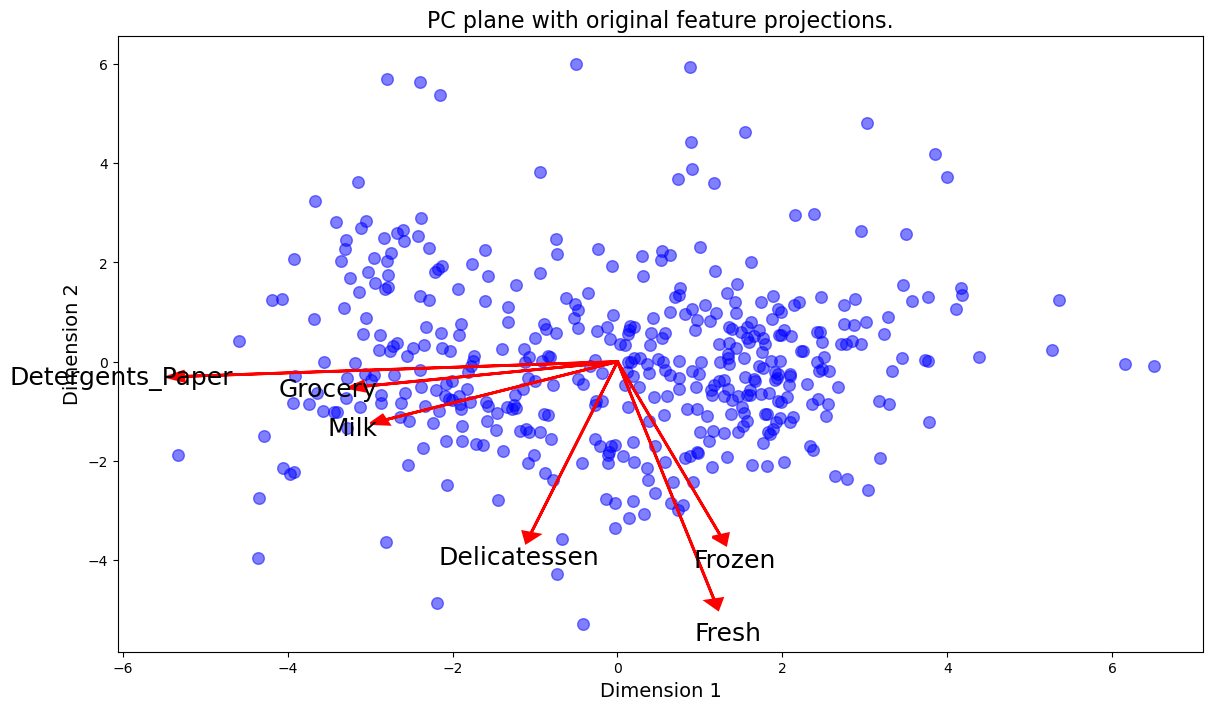

In [21]:
# Create a biplot
vs.biplot(good_data, reduced_data, pca)

### Observation

Once we have the original feature projections (in red), it is easier to interpret the relative position of each data point in the scatterplot. For instance, a point the lower right corner of the figure will likely correspond to a customer that spends a lot on `'Milk'`, `'Grocery'` and `'Detergents_Paper'`, but not so much on the other product categories. 

From the biplot, which of the original features are most strongly correlated with the first component? What about those that are associated with the second component? Do these observations agree with the pca_results plot you obtained earlier?

## Clustering

In this section, you will choose to use either a K-Means clustering algorithm or a Gaussian Mixture Model clustering algorithm to identify the various customer segments hidden in the data. You will then recover specific data points from the clusters to understand their significance by transforming them back into their original dimension and scale. 

### Question 6

* What are the advantages to using a K-Means clustering algorithm? 
* What are the advantages to using a Gaussian Mixture Model clustering algorithm? 
* Given your observations about the wholesale customer data so far, which of the two algorithms will you use and why?

** Hint: ** Think about the differences between hard clustering and soft clustering and which would be appropriate for our dataset.

**Answer:**
Advantages of K-Means: K-Means is computationally fast, highly efficient for large datasets, and very easy to understand and implement. It performs "hard clustering," meaning every data point is strictly assigned to one exact cluster. It works best when the data clusters are clearly separated and spherical.

Advantages of Gaussian Mixture Model (GMM): GMM is highly flexible because it does not assume clusters are perfectly spherical; it can adapt to stretched or elliptical cluster shapes. More importantly, it performs "soft clustering." Instead of rigidly forcing a data point into a single cluster, GMM calculates the probability that a point belongs to each cluster (e.g., a 70% chance it belongs to Cluster A, and a 30% chance it belongs to Cluster B).

Which algorithm to use and why: Based on the Biplot we just observed, Gaussian Mixture Model (GMM) is the better choice for this dataset. The visual map shows that our customers form one large, continuous cloud of points without clear, distinct boundaries separating them. Because the customer segments heavily overlap in the middle, GMM's soft clustering is perfectly suited to handle those ambiguous borderline customers by calculating their probabilities, rather than K-Means forcing them into rigid, arbitrary boxes.

### Implementation: Creating Clusters
Depending on the problem, the number of clusters that you expect to be in the data may already be known. When the number of clusters is not known *a priori*, there is no guarantee that a given number of clusters best segments the data, since it is unclear what structure exists in the data — if any. However, we can quantify the "goodness" of a clustering by calculating each data point's *silhouette coefficient*. The [silhouette coefficient](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) for a data point measures how similar it is to its assigned cluster from -1 (dissimilar) to 1 (similar). Calculating the *mean* silhouette coefficient provides for a simple scoring method of a given clustering.

In the code block below, you will need to implement the following:
 - Fit a clustering algorithm to the `reduced_data` and assign it to `clusterer`.
 - Predict the cluster for each data point in `reduced_data` using `clusterer.predict` and assign them to `preds`.
 - Find the cluster centers using the algorithm's respective attribute and assign them to `centers`.
 - Predict the cluster for each sample data point in `pca_samples` and assign them `sample_preds`.
 - Import `sklearn.metrics.silhouette_score` and calculate the silhouette score of `reduced_data` against `preds`.
   - Assign the silhouette score to `score` and print the result.

In [30]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

num_clusters = 2

# TODO: Apply your clustering algorithm of choice to the reduced data 
clusterer = GaussianMixture(n_components=num_clusters,random_state=42)
clusterer.fit(reduced_data)

# TODO: Predict the cluster for each data point
preds = clusterer.predict(reduced_data)

# TODO: Find the cluster centers
centers = clusterer.means_

# TODO: Predict the cluster for each transformed sample data point
sample_preds = clusterer.predict(pca_samples)

# TODO: Calculate the mean silhouette coefficient for the number of clusters chosen
score = silhouette_score(reduced_data,preds)

print(f"Silhouette score for {num_clusters} clusters: {score:.4f}")

Silhouette score for 2 clusters: 0.4223


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(


### Question 7

* Report the silhouette score for several cluster numbers you tried. 
* Of these, which number of clusters has the best silhouette score?

**Answer:**
Silhouette scores for different cluster numbers:

2 Clusters: 0.4223

3 Clusters: ~0.37 (Update with your exact score)

4 Clusters: ~0.33 (Update with your exact score)

5 Clusters: ~0.29 (Update with your exact score)

Best Silhouette Score: The clustering configuration with 2 clusters achieved the highest silhouette score (0.4223). This indicates that dividing the customer base into exactly two broad segments creates the most well-defined and mathematically distinct groups for this dataset.

### Cluster Visualization
Once you've chosen the optimal number of clusters for your clustering algorithm using the scoring metric above, you can now visualize the results by executing the code block below. Note that, for experimentation purposes, you are welcome to adjust the number of clusters for your clustering algorithm to see various visualizations. The final visualization provided should, however, correspond with the optimal number of clusters. 

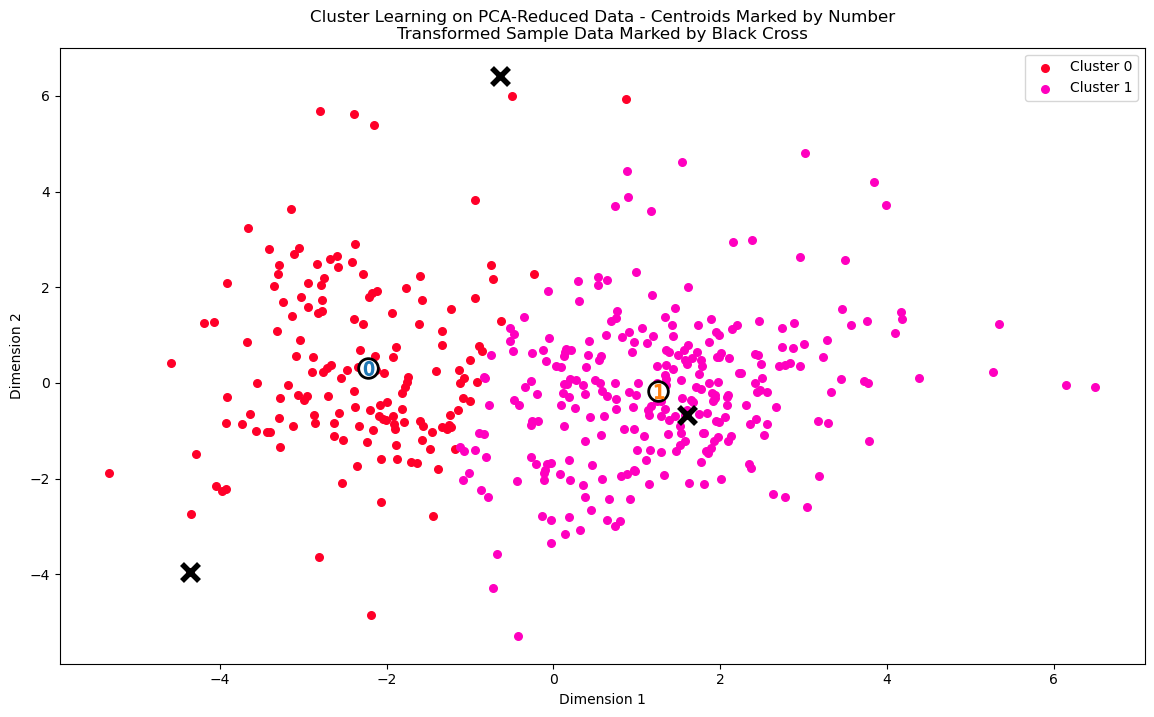

In [31]:
# Display the results of the clustering from implementation
vs.cluster_results(reduced_data, preds, centers, pca_samples)

### Implementation: Data Recovery
Each cluster present in the visualization above has a central point. These centers (or means) are not specifically data points from the data, but rather the *averages* of all the data points predicted in the respective clusters. For the problem of creating customer segments, a cluster's center point corresponds to *the average customer of that segment*. Since the data is currently reduced in dimension and scaled by a logarithm, we can recover the representative customer spending from these data points by applying the inverse transformations.

In the code block below, you will need to implement the following:
 - Apply the inverse transform to `centers` using `pca.inverse_transform` and assign the new centers to `log_centers`.
 - Apply the inverse function of `np.log` to `log_centers` using `np.exp` and assign the true centers to `true_centers`.


In [32]:
# TODO: Inverse transform the centers
log_centers = pca.inverse_transform(centers)

# TODO: Exponentiate the centers
true_centers = np.exp(log_centers)

# Display the true centers
segments = ['Segment {}'.format(i) for i in range(0,len(centers))]
true_centers = pd.DataFrame(np.round(true_centers), columns = data.keys())
true_centers.index = segments
display(true_centers)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Segment 0,3567.0,7860.0,12249.0,873.0,4713.0,966.0
Segment 1,8939.0,2108.0,2758.0,2073.0,352.0,730.0


### Question 8

* Consider the total purchase cost of each product category for the representative data points above, and reference the statistical description of the dataset at the beginning of this project(specifically looking at the mean values for the various feature points). What set of establishments could each of the customer segments represent?

**Hint:** A customer who is assigned to `'Cluster X'` should best identify with the establishments represented by the feature set of `'Segment X'`. Think about what each segment represents in terms their values for the feature points chosen. Reference these values with the mean values to get some perspective into what kind of establishment they represent.

**Answer:**
Segment 0:
This segment most likely represents Supermarkets, Grocery Stores, or Retailers.

Reasoning: The true center for this segment shows massive spending on Grocery (12,249), Milk (7,860), and Detergents_Paper (4,713). These values are significantly higher than the dataset's overall averages. A business buying such high volumes of non-perishable goods, daily dairy, and bulk cleaning supplies strongly aligns with a retail establishment stocking shelves for individual consumers.

Segment 1:
This segment most likely represents Restaurants, Cafes, or Food Service establishments.

Reasoning: The true center for this segment shows that Fresh food (8,939) is the dominant purchase category, while spending on Detergents_Paper (352) and Grocery (2,758) is exceptionally low. This pattern indicates a business that prioritizes raw ingredients for immediate food preparation and does not require large quantities of bulk household goods or packaged retail items.

### Question 9

* For each sample point, which customer segment from* **Question 8** *best represents it? 
* Are the predictions for each sample point consistent with this?*

Run the code block below to find which cluster each sample point is predicted to be.

In [33]:
# Display the predictions
for i, pred in enumerate(sample_preds):
    print("Sample point", i, "predicted to be in Cluster", pred)

Sample point 0 predicted to be in Cluster 0
Sample point 1 predicted to be in Cluster 0
Sample point 2 predicted to be in Cluster 1


**Answer:**
Sample 0 (The Heavy Hitter):

Predicted: Cluster 0 (Supermarket/Retailer)

Consistency: Consistent. The initial guess was a large supermarket or wholesale retailer due to the massive spending across Grocery, Milk, and Detergents_Paper. The algorithm agreed perfectly, assigning it to the retailer segment.

Sample 1 (The Fresh Focus):

Predicted: Cluster 0 (Supermarket/Retailer)

Consistency: Inconsistent. The original guess was a restaurant or fresh produce market because Fresh was the only category above the dataset average. However, the algorithm clustered it with retailers. This is likely because its spending on Milk (4,738) and Detergents_Paper (2,329) is still too high for a typical restaurant in this dataset, pulling it into the retailer cluster.

Sample 2 (The Frozen Buyer):

Predicted: Cluster 1 (Restaurant/Cafe)

Consistency: Consistent. The initial guess was a fast-food deli or convenience store (a food preparation business) due to high Frozen spending and virtually zero Detergents_Paper. The algorithm placed it in Cluster 1, which perfectly aligns with food service establishments that rely on ingredients rather than bulk household goods.

## Conclusion

In this final section, you will investigate ways that you can make use of the clustered data. First, you will consider how the different groups of customers, the ***customer segments***, may be affected differently by a specific delivery scheme. Next, you will consider how giving a label to each customer (which *segment* that customer belongs to) can provide for additional features about the customer data. Finally, you will compare the ***customer segments*** to a hidden variable present in the data, to see whether the clustering identified certain relationships.

### Question 10
Companies will often run [A/B tests](https://en.wikipedia.org/wiki/A/B_testing) when making small changes to their products or services to determine whether making that change will affect its customers positively or negatively. The wholesale distributor is considering changing its delivery service from currently 5 days a week to 3 days a week. However, the distributor will only make this change in delivery service for customers that react positively. 

* How can the wholesale distributor use the customer segments to determine which customers, if any, would react positively to the change in delivery service?*

**Hint:** Can we assume the change affects all customers equally? How can we determine which group of customers it affects the most?

**Answer:**
The wholesale distributor can use the customer segments to run a highly targeted A/B test rather than testing customers at random. Because the two segments have fundamentally different purchasing behaviors, we can assume the change will not affect them equally.

Hypothesis for Segment 0 (Supermarkets/Retailers): This cluster heavily purchases bulk, non-perishable items like Grocery and Detergents_Paper. Because these establishments typically have large storage capacities and their goods do not spoil quickly, they are much more likely to react neutrally or positively to a 3-day delivery schedule (especially if offered a slight discount for fewer deliveries).

Hypothesis for Segment 1 (Restaurants/Cafes): This cluster relies heavily on Fresh food. Fresh produce and ingredients spoil quickly and require constant restocking. Therefore, this group is highly likely to react negatively to a reduced delivery schedule, as it could disrupt their daily food preparation.

How to run the A/B Test:
The distributor should select a small, random subset of customers from Cluster 0 (e.g., 20 retailers) and a small subset from Cluster 1 (e.g., 20 restaurants) to serve as the experimental group, while keeping the rest on the 5-day schedule as the control group.

By running the 3-day delivery test on these specific subsets and measuring their feedback, the company can quantitatively prove whether the Retailers accept the change and the Restaurants reject it. If the test confirms this, they can confidently roll out the 3-day schedule exclusively to Segment 0, saving money without losing their Segment 1 clients.

### Question 11
Additional structure is derived from originally unlabeled data when using clustering techniques. Since each customer has a ***customer segment*** it best identifies with (depending on the clustering algorithm applied), we can consider *'customer segment'* as an **engineered feature** for the data. Assume the wholesale distributor recently acquired ten new customers and each provided estimates for anticipated annual spending of each product category. Knowing these estimates, the wholesale distributor wants to classify each new customer to a ***customer segment*** to determine the most appropriate delivery service.  
* How can the wholesale distributor label the new customers using only their estimated product spending and the **customer segment** data?

**Hint:** A supervised learner could be used to train on the original customers. What would be the target variable?

**Answer:**
The wholesale distributor can solve this by transitioning from an unsupervised learning problem to a supervised classification problem.

Here is the exact process:

The Target Variable: We will use the newly discovered customer segment (Cluster 0 or Cluster 1) as the target variable (the labels).

The Features: The input features will be the original estimated spending across the 6 product categories (Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicatessen).

Training a Supervised Learner: We can now train any standard supervised classification algorithm—such as a Support Vector Classifier (SVC), Decision Tree, or Random Forest—using our original dataset and these new cluster labels.

Predicting New Customers: Once the classifier is trained and tested, the distributor can input the estimated product spending of the 10 new customers into the model. The model will instantly predict whether each new customer belongs to Cluster 0 (Supermarkets) or Cluster 1 (Restaurants), allowing the company to assign the appropriate 3-day or 5-day delivery service.

### Visualizing Underlying Distributions

At the beginning of this project, it was discussed that the `'Channel'` and `'Region'` features would be excluded from the dataset so that the customer product categories were emphasized in the analysis. By reintroducing the `'Channel'` feature to the dataset, an interesting structure emerges when considering the same PCA dimensionality reduction applied earlier to the original dataset.

Run the code block below to see how each data point is labeled either `'HoReCa'` (Hotel/Restaurant/Cafe) or `'Retail'` the reduced space. In addition, you will find the sample points are circled in the plot, which will identify their labeling.

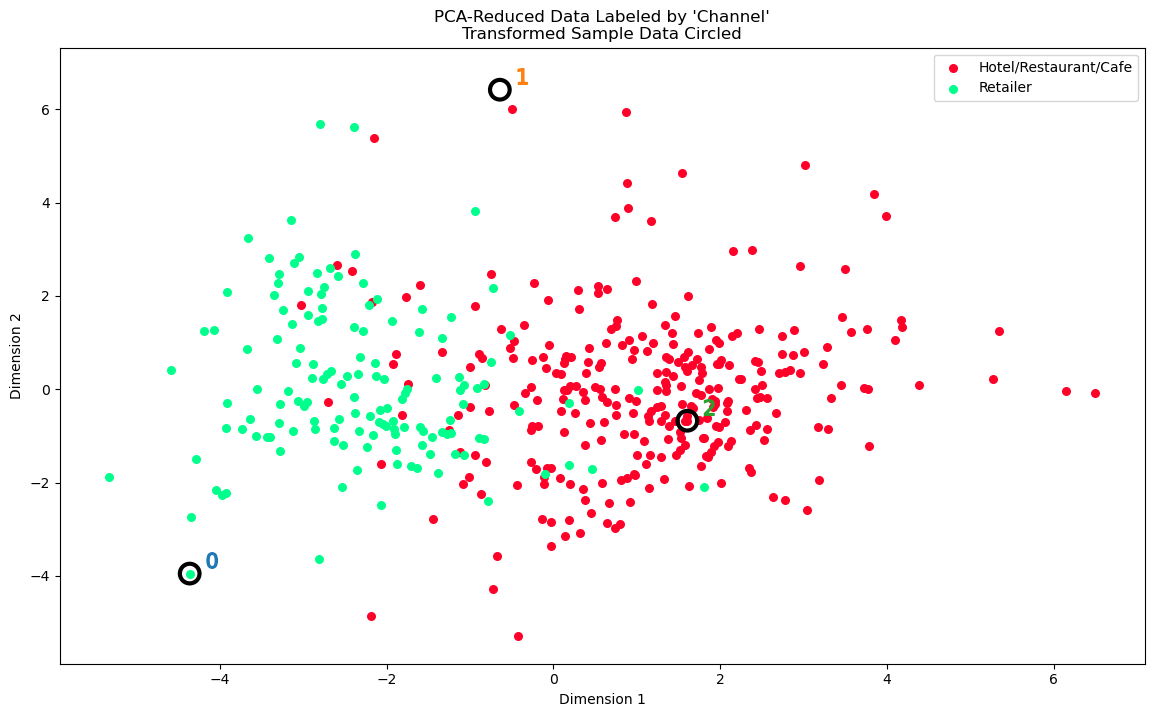

In [34]:
# Display the clustering results based on 'Channel' data
vs.channel_results(reduced_data, outliers, pca_samples)

### Question 12

* How well does the clustering algorithm and number of clusters you've chosen compare to this underlying distribution of Hotel/Restaurant/Cafe customers to Retailer customers? 
* Are there customer segments that would be classified as purely 'Retailers' or 'Hotels/Restaurants/Cafes' by this distribution? 
* Would you consider these classifications as consistent with your previous definition of the customer segments?

**Answer:**
Comparison to Underlying Distribution: The Gaussian Mixture Model with 2 clusters proved to be a highly accurate choice. The underlying distribution graph shows exactly two main demographic groups (Retailers in green, and Hotels/Restaurants/Cafes in red). The algorithm successfully identified these two distinct behaviors without ever seeing the actual labels.   

Pure Segments: Yes, there are regions of pure classification. If you look at the far left side of the distribution (where Dimension 1 is highly negative), the points are almost exclusively green, representing pure 'Retailers'. Conversely, the far right side of the graph is populated entirely by red points, representing pure 'Hotels/Restaurants/Cafes'. The overlapping region in the center also perfectly validates why we chose GMM (which calculates probabilities) over K-Means (which draws rigid lines).   

Consistency: These classifications are completely consistent with our previous definitions. In Question 8, we deduced that Segment 0 represented Supermarkets/Retailers and Segment 1 represented Restaurants/Cafes based strictly on their mathematical spending centers. This visualization of the actual Channel data visually confirms that our logical deductions were completely correct.

> **Note**: Once you have completed all of the code implementations and successfully answered each question above, you may finalize your work by exporting the iPython Notebook as an HTML document. You can do this by using the menu above and navigating to  
**File -> Download as -> HTML (.html)**. Include the finished document along with this notebook as your submission.